In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1) (1).zip


In [3]:
import os

print(os.listdir("/content"))

['.config', 'archive (1) (1).zip', 'archive (1).zip', 'sample_data']


In [5]:
import zipfile
import os

zip_path = "/content/archive (1) (1).zip"
extract_path = "/content/playstore_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['googleplaystore_user_reviews.csv', 'license.txt', 'googleplaystore.csv']


In [6]:
import os

for root, dirs, files in os.walk("/content/playstore_data"):
    for file in files:
        print(file)

googleplaystore_user_reviews.csv
license.txt
googleplaystore.csv


In [7]:
import pandas as pd

df = pd.read_csv("/content/playstore_data/googleplaystore.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [8]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

Dataset Shape:
(10841, 13)

Missing Values:
App                  0
Category             0
Rating            1474
Reviews              0
Size 

In [9]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Remove rows with missing important values
df.dropna(subset=['App', 'Category', 'Rating'], inplace=True)

# Check cleaned dataset
print("Data cleaning completed!")

print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicate Rows:", df.duplicated().sum())

print("Cleaned Dataset Shape:", df.shape)

Data cleaning completed!
Remaining Missing Values: 8
Remaining Duplicate Rows: 0
Cleaned Dataset Shape: (8893, 13)


In [10]:
# Convert Reviews into numeric values
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

# Convert Installs into numeric values
df['Installs'] = (
    df['Installs'].astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')

# Convert Price into numeric values
df['Price'] = (
    df['Price'].astype(str)
    .str.replace('$', '', regex=False)
)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

print("Column conversion completed!")
print(df[['App', 'Reviews', 'Installs', 'Price']].head())
print("\nUpdated Data Types:")
print(df[['Reviews', 'Installs', 'Price']].dtypes)

Column conversion completed!
                                                 App   Reviews    Installs  \
0     Photo Editor & Candy Camera & Grid & ScrapBook     159.0     10000.0   
1                                Coloring book moana     967.0    500000.0   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   87510.0   5000000.0   
3                              Sketch - Draw & Paint  215644.0  50000000.0   
4              Pixel Draw - Number Art Coloring Book     967.0    100000.0   

   Price  
0    0.0  
1    0.0  
2    0.0  
3    0.0  
4    0.0  

Updated Data Types:
Reviews     float64
Installs    float64
Price       float64
dtype: object


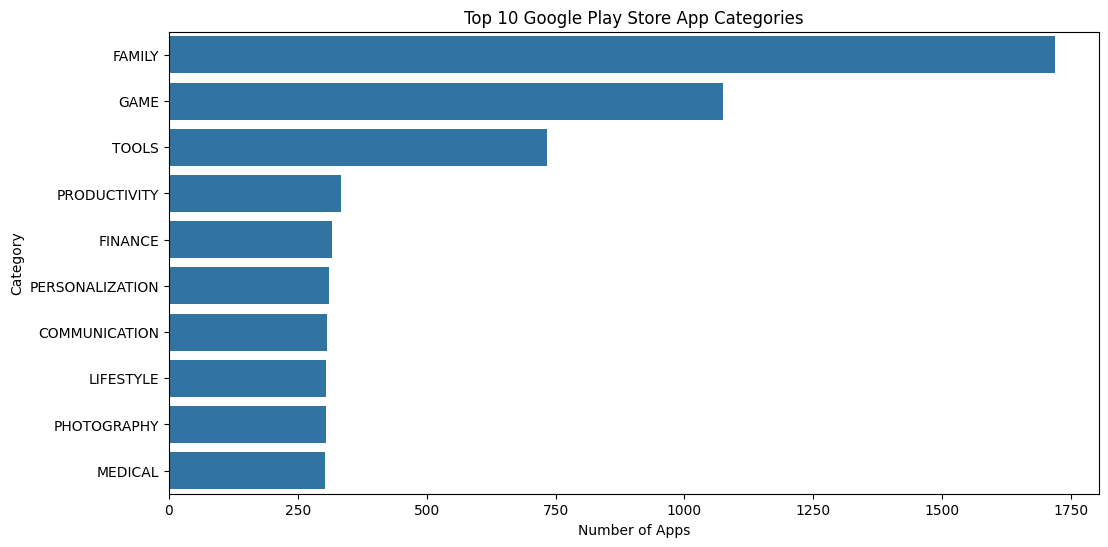

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

top_categories = df['Category'].value_counts().head(10)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Google Play Store App Categories")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.show()

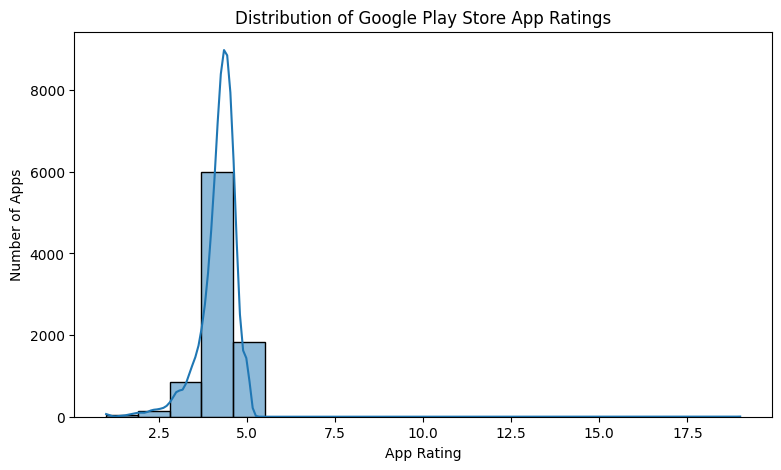

In [12]:
plt.figure(figsize=(9,5))

sns.histplot(df['Rating'], bins=20, kde=True)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("App Rating")
plt.ylabel("Number of Apps")
plt.show()

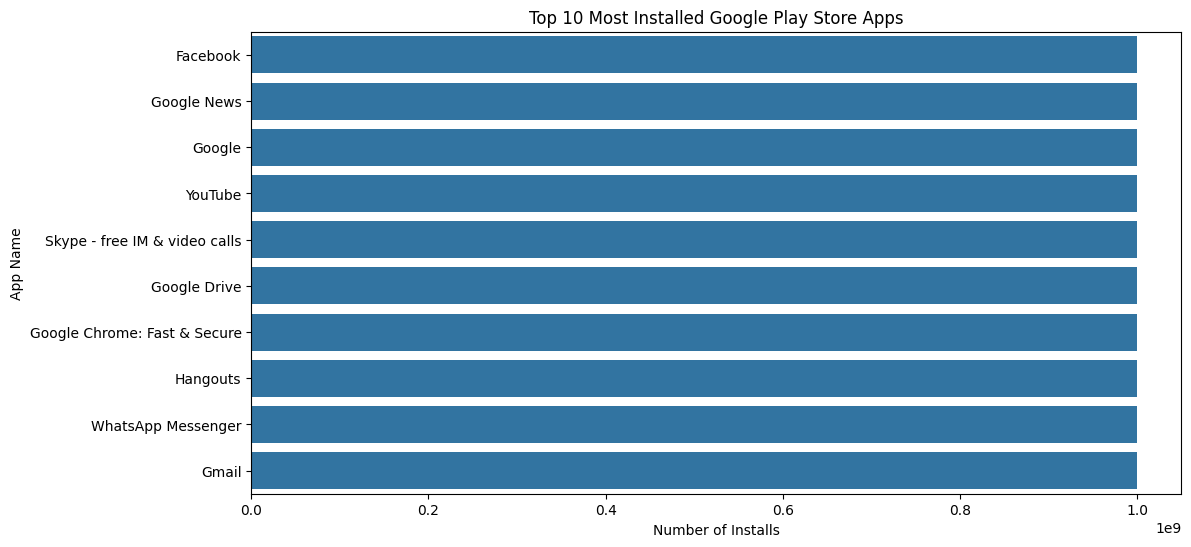

In [13]:
top_apps = df.groupby('App')['Installs'].max().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_apps.values,
    y=top_apps.index
)

plt.title("Top 10 Most Installed Google Play Store Apps")
plt.xlabel("Number of Installs")
plt.ylabel("App Name")
plt.show()

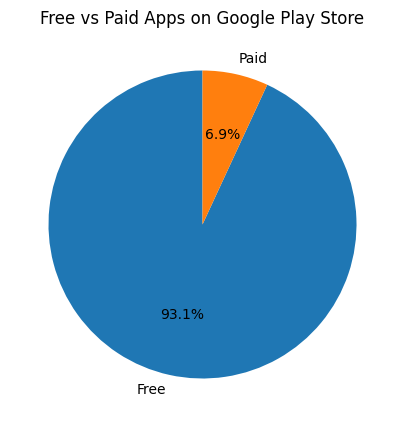

Type
Free    8279
Paid     614
Name: count, dtype: int64


In [14]:
df['Type'] = df['Price'].apply(
    lambda x: 'Free' if x == 0 else 'Paid'
)

type_counts = df['Type'].value_counts()

plt.figure(figsize=(7,5))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Free vs Paid Apps on Google Play Store")
plt.show()

print(type_counts)

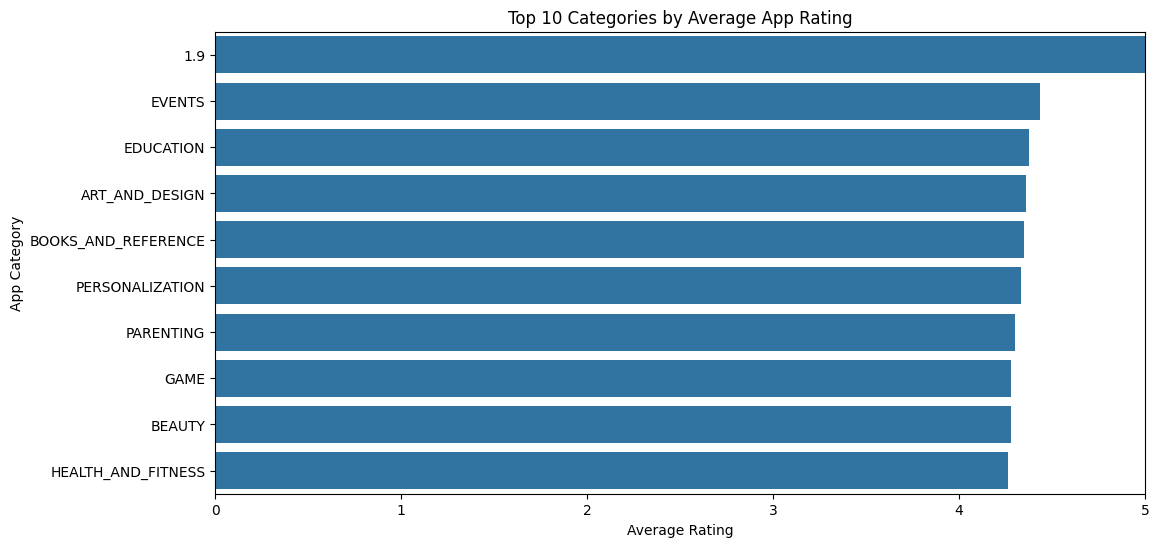

In [15]:
category_rating = df.groupby('Category')['Rating'].mean().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_rating.values,
    y=category_rating.index
)

plt.title("Top 10 Categories by Average App Rating")
plt.xlabel("Average Rating")
plt.ylabel("App Category")
plt.xlim(0, 5)
plt.show()

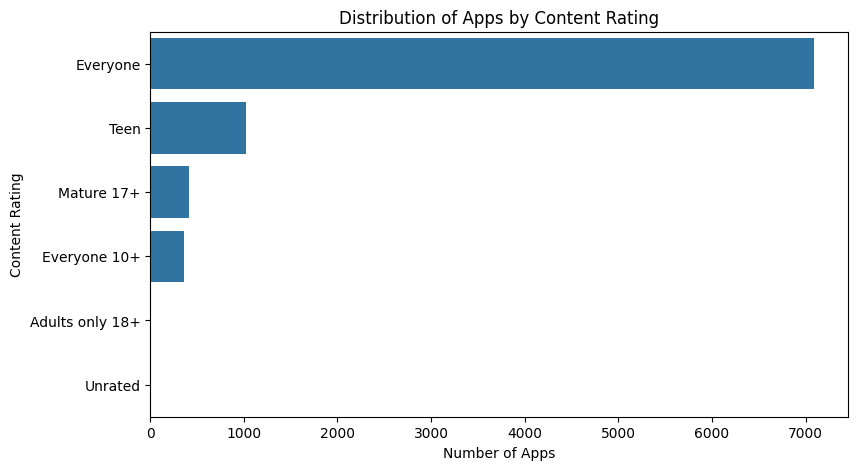

In [16]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    y='Content Rating',
    order=df['Content Rating'].value_counts().index
)

plt.title("Distribution of Apps by Content Rating")
plt.xlabel("Number of Apps")
plt.ylabel("Content Rating")
plt.show()

## Project Observations

1. **App Categories:** The analysis identifies the categories containing the highest number of applications.
2. **App Ratings:** Most applications have ratings within the common rating range, helping us understand user satisfaction.
3. **App Installs:** Popular applications receive a higher number of downloads.
4. **Free vs Paid Apps:** The analysis compares free and paid applications on Google Play Store.
5. **Category Ratings:** Average ratings help identify categories with better user feedback.
6. **Content Ratings:** Apps are classified according to their intended audience and age suitability.

## Conclusion

This project analyses Google Play Store applications using Python data analytics techniques. Data cleaning, exploration and visualization were performed to understand app categories, ratings, installations, pricing and content ratings. The analysis provides useful insights into application popularity and user preferences.